<a href="https://colab.research.google.com/github/rmadatt/AI-Newton-StudyGroupAfrica/blob/main/Toy_AI_Newton.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

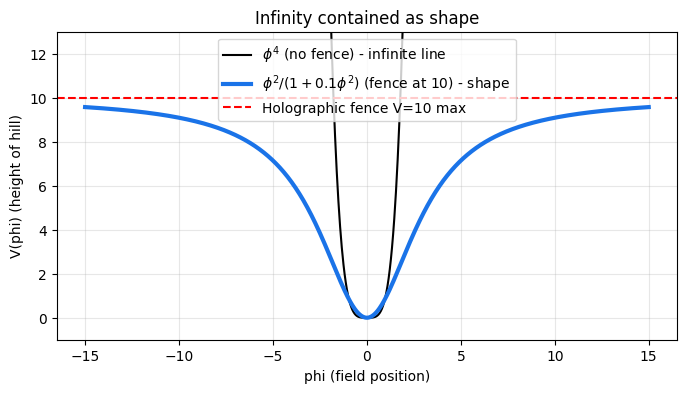

In [1]:
import numpy as np
import matplotlib.pyplot as plt

phi = np.linspace(-15, 15, 1000)

V_power = phi**4
V_power = np.clip(V_power, 0, 20)  # clipped for viewing

V_toy = phi**2 / (1 + 0.1*phi**2)  # your toy - infinity contained

plt.figure(figsize=(8,4))
plt.plot(phi, V_power, label=r'$\phi^4$ (no fence) - infinite line', color='black')
plt.plot(phi, V_toy, label=r'$\phi^2/(1+0.1\phi^2)$ (fence at 10) - shape', color='#1a73e8', lw=3)
plt.axhline(10, ls='--', color='red', label='Holographic fence V=10 max')
plt.ylim(-1, 13)
plt.xlabel('phi (field position)')
plt.ylabel('V(phi) (height of hill)')
plt.title('Infinity contained as shape')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

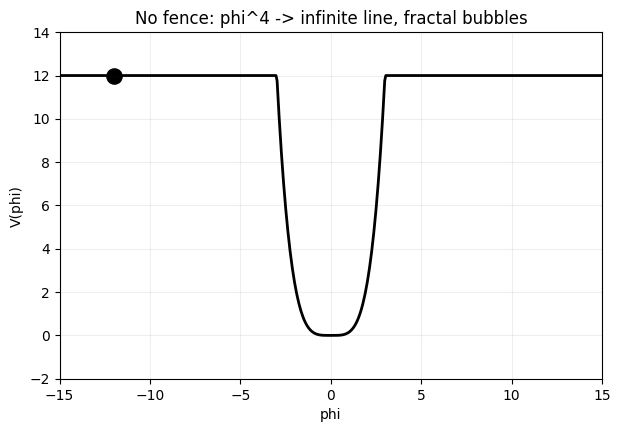

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

phi = np.linspace(-15, 15, 500)

def V_toy(p): return p**2 / (1 + 0.1*p**2)
def V_steep(p): return np.clip(p**4 * 0.15, 0, 12)

fig, ax = plt.subplots(figsize=(7,4.5))

def update(frame):
    ax.clear()
    ax.set_xlim(-15, 15)
    ax.set_ylim(-2, 14)
    ax.set_xlabel('phi')
    ax.set_ylabel('V(phi)')
    ax.grid(alpha=0.2)

    t = frame / 100

    if t < 0.35:
        progress = t / 0.35
        V = V_steep(phi)
        ax.plot(phi, V, 'k', lw=2)
        ball_phi = -12 + progress*24
        ax.scatter(ball_phi, V_steep(ball_phi), s=120, c='k')
        ax.set_title('No fence: phi^4 -> infinite line, fractal bubbles', fontsize=12)

    elif t < 0.6:
        progress = (t-0.35)/0.25
        V = (1-progress)*V_steep(phi) + progress*V_toy(phi)
        ax.plot(phi, V, 'k', lw=2)
        ax.axhline(10, ls='--', c='r', alpha=progress, label='Fence V=10 max')
        ax.set_title('Fence appears: Infinity contained as shape', fontsize=12)
        ax.legend()

    elif t < 0.85:
        progress = (t-0.6)/0.25
        V = V_toy(phi)
        ax.plot(phi, V, color='#1a73e8', lw=3, label='phi^2/(1+0.1 phi^2)')
        ax.axhline(10, ls='--', c='r', label='Fence V=10 max')
        ball_phi = 12 * (1-progress*1.5)
        ax.scatter(ball_phi, V_toy(ball_phi), s=150, c='#1a73e8', edgecolors='k', zorder=5)
        ax.set_title('Plateau: Smooth exit to one finite universe', fontsize=12)
        ax.legend()

    else:
        # LAST SLIDE - your heading
        progress = (t-0.85)/0.15
        V = V_toy(phi)
        ax.plot(phi, V, color='#1a73e8', lw=3, alpha=0.3)
        ax.axhline(10, ls='--', c='r', alpha=0.3)
        # Your heading as the final slide
        ax.text(0, 8, 'AI provided the code,\nI provided the ideas.',
                ha='center', va='center', fontsize=18, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.6', facecolor='white', edgecolor='black', lw=2))
        ax.text(0, 4.5, 'V = phi² / (1 + 0.1*phi²)\nInfinity contained as shape - finite but no edge',
                ha='center', fontsize=11, style='italic')
        ax.set_title('StudyGroupAfrica - AI-Newton', fontsize=12)

ani = FuncAnimation(fig, update, frames=100, interval=90)
HTML(ani.to_jshtml())

# Save with last slide included:
# ani.save('plateau_with_heading.gif', writer='pillow', fps=12)